# 1. Tugas Pendahuluan

## 1.2 Mempelajari Penggunaan Driver Neo4J

In [126]:
from neo4j import GraphDatabase, RoutingControl

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "admin123")

# Hide

In [3]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j"
    )

In [4]:
def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

with GraphDatabase.driver(URI, auth=AUTH, ) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


## 1.3 Melakukan proses Impor Data dari RetailRocket ke Database Neo4J

In [5]:
from neo4j import GraphDatabase
driver = GraphDatabase.driver(uri=URI, auth=AUTH)
session = driver.session(database="system")

In [6]:
import argparse
import os

def parse_arguments(argv=None):
    parser = argparse.ArgumentParser(
        description="Impor dataset RetailRocket (events.csv) ke database Neo4J."
    )
    parser.add_argument("-u", "--user", default="neo4j", help="Username Neo4j (default: neo4j)")
    parser.add_argument("-p", "--password", default="admin123", help="Password Neo4J")
    parser.add_argument("-b", "--bolt", default="neo4j://127.0.0.1:7687", help="Neo4J URI / Bolt")
    parser.add_argument("-s", "--source", default="ecommerce-dataset", help="Folder sumber data")
    # Di notebook, argv=[] supaya argumen milik Jupyter (--f=...) tidak ikut dibaca
    return parser.parse_args(argv)

args = parse_arguments([])

csv_file_path = os.path.join(args.source, "events.csv")
if not os.path.exists(csv_file_path):
    raise FileNotFoundError(f"File '{csv_file_path}' tidak ditemukan!")


In [7]:
try:
    driver = GraphDatabase.driver(
        args.bolt, auth=(args.user, args.password)
    )
    driver.verify_connectivity()
    print("Berhasil terhubung ke Neo4j.")
except Exception as e:
    raise RuntimeError(f"Gagal terhubung ke database: {e}") from e

Berhasil terhubung ke Neo4j.


In [8]:
import pandas as pd
from tqdm.auto import tqdm


def create_constraints(session):
    # Constraint unik sekaligus membuat index, sehingga MERGE jauh lebih cepat
    session.run(
        "CREATE CONSTRAINT visitor_id IF NOT EXISTS "
        "FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE"
    )
    session.run(
        "CREATE CONSTRAINT item_id IF NOT EXISTS "
        "FOR (i:Item) REQUIRE i.itemId IS UNIQUE"
    )


def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

d:\uts-graf\myvenv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [15]:
batch_size = 10000

with driver.session(database="neo4j") as session:
    create_constraints(session)

    print(f"Membaca file data dari: {csv_file_path}")
    chunks = pd.read_csv(csv_file_path, chunksize=batch_size)

    # Jumlah baris data (tanpa header) untuk progress bar
    with open(csv_file_path, encoding="utf-8") as f:
        total_rows = sum(1 for _ in f) - 1
    total_chunks = (total_rows // batch_size) + 1

    print("Memulai proses impor data ke Neo4j...")
    for chunk in tqdm(
        chunks, total=total_chunks, desc="Mengimpor Batch Data"
    ):
        # Membersihkan data null/NaN pada transactionid
        chunk["transactionid"] = (
            chunk["transactionid"].fillna("").astype(str)
        )

        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

driver.close()
print("Proses impor berhasil.")

Membaca file data dari: ecommerce-dataset\events.csv
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data: 100%|██████████| 276/276 [05:14<00:00,  1.14s/it]

Proses impor berhasil.


# 2. Soal

## 2.1 Wrangling dan EDA (Maks. skor: 45)

In [127]:
import pandas as pd
def read_item_properties(files):
    props = pd.concat(
        (pd.read_csv(f, usecols=["timestamp", "itemid", "property"]) for f in files),
        ignore_index=True,
    )
    # Timestamp dalam milidetik -> unit="ms"
    props["datetime"] = pd.to_datetime(props["timestamp"], unit="ms")
    return props


In [128]:
item_part1 = read_item_properties(files=["ecommerce-dataset/item_properties_part1.csv"])
item_part1

,timestamp,itemid,property,datetime
0,1435460400000,460429,categoryid,2015-06-28 03:00:00
1,1441508400000,206783,888,2015-09-06 03:00:00
2,1439089200000,395014,400,2015-08-09 03:00:00
3,1431226800000,59481,790,2015-05-10 03:00:00
4,1431831600000,156781,917,2015-05-17 03:00:00
...,...,...,...,...
10999994,1439694000000,86599,categoryid,2015-08-16 03:00:00
10999995,1435460400000,153032,1066,2015-06-28 03:00:00
10999996,1440298800000,421788,888,2015-08-23 03:00:00
10999997,1437879600000,159792,400,2015-07-26 03:00:00


In [129]:
item_part2 = read_item_properties(files=["ecommerce-dataset/item_properties_part2.csv"])
item_part2

,timestamp,itemid,property,datetime
0,1433041200000,183478,561,2015-05-31 03:00:00
1,1439694000000,132256,976,2015-08-16 03:00:00
2,1435460400000,420307,921,2015-06-28 03:00:00
3,1431831600000,403324,917,2015-05-17 03:00:00
4,1435460400000,230701,521,2015-06-28 03:00:00
...,...,...,...,...
9275898,1433646000000,236931,929,2015-06-07 03:00:00
9275899,1440903600000,455746,6,2015-08-30 03:00:00
9275900,1439694000000,347565,686,2015-08-16 03:00:00
9275901,1433646000000,287231,867,2015-06-07 03:00:00


In [130]:
def filter_period(df, start, end, col="datetime"):
    mask = (df[col] >= pd.Timestamp(start)) & (df[col] < pd.Timestamp(end))
    return df[mask]


P1 = ("2015-05-07", "2015-06-07")  # fold training
P2 = ("2015-08-28", "2015-09-18")  # fold testing


In [131]:
item_part1_filtered = filter_period(item_part1, *P1)
item_part1_filtered

,timestamp,itemid,property,datetime
3,1431226800000,59481,790,2015-05-10 03:00:00
4,1431831600000,156781,917,2015-05-17 03:00:00
7,1431831600000,264312,6,2015-05-17 03:00:00
21,1431226800000,344365,159,2015-05-10 03:00:00
31,1431831600000,246186,764,2015-05-17 03:00:00
...,...,...,...,...
10999980,1433041200000,251050,441,2015-05-31 03:00:00
10999981,1431831600000,413690,631,2015-05-17 03:00:00
10999984,1431226800000,55502,776,2015-05-10 03:00:00
10999989,1433041200000,56123,348,2015-05-31 03:00:00


In [132]:
item_part1_filtered.to_csv("ecommerce-dataset/item_properties_part1_filtered.csv", index=False)

In [133]:
item_part2_filtered = filter_period(item_part2, *P2)
item_part2_filtered

,timestamp,itemid,property,datetime
28,1441508400000,200318,962,2015-09-06 03:00:00
34,1441508400000,77208,468,2015-09-06 03:00:00
46,1441508400000,233854,225,2015-09-06 03:00:00
54,1441508400000,281368,888,2015-09-06 03:00:00
78,1442113200000,412689,544,2015-09-13 03:00:00
...,...,...,...,...
9275862,1441508400000,369875,888,2015-09-06 03:00:00
9275871,1441508400000,27441,720,2015-09-06 03:00:00
9275880,1441508400000,107574,962,2015-09-06 03:00:00
9275899,1440903600000,455746,6,2015-08-30 03:00:00


In [134]:
item_part2_filtered.to_csv("ecommerce-dataset/item_properties_part2_filtered.csv", index=False)

### 2.1.3 Komposisi Subgraph

Graf hasil impor berbentuk **bipartit**: simpul `Visitor` → relasi interaksi → simpul `Item`, dengan 3 jenis relasi (`VIEWED`, `ADDED_TO_CART`, `BOUGHT`) yang masing-masing menyimpan properti `timestamp` (unix epoch, milidetik).

**Subgraph** per periode didefinisikan sebagai seluruh relasi yang `timestamp`-nya berada di rentang `[start, end)`, beserta simpul `Visitor` dan `Item` yang terhubung oleh relasi tersebut.

Penjelasan CYPHER yang digunakan:

1. **Komposisi simpul (seluruh graf)**
   ```cypher
   MATCH (n)
   UNWIND labels(n) AS label
   RETURN label AS jenis_simpul, count(*) AS jumlah
   ORDER BY jumlah DESC
   ```
   - `MATCH (n)`: mengambil semua simpul.
   - `labels(n)`: mengembalikan list label sebuah simpul (satu simpul bisa punya >1 label); `UNWIND` memecah list itu menjadi satu baris per label.
   - `count(*)` dengan `label` sebagai kunci pengelompokan (implicit `GROUP BY`) → jumlah simpul per jenis.

2. **Komposisi relasi (seluruh graf)**
   ```cypher
   MATCH ()-[r]->()
   RETURN type(r) AS jenis_relasi, count(*) AS jumlah
   ```
   - `()-[r]->()`: semua relasi berarah; `type(r)` mengembalikan nama jenis relasi.

3. **Komposisi simpul pada subgraph periode**
   ```cypher
   MATCH (v:Visitor)-[r]->(i:Item)
   WHERE $start <= r.timestamp < $end
   RETURN count(DISTINCT v) AS Visitor, count(DISTINCT i) AS Item, count(r) AS total_relasi
   ```
   - `$start` dan `$end` adalah **parameter** (dikirim dari Python dalam epoch milidetik), bukan string yang ditempel, sehingga aman dan query plan bisa di-cache.
   - `$start <= r.timestamp < $end`: perbandingan berantai; batas awal inklusif, batas akhir eksklusif.
   - `count(DISTINCT v)`: satu visitor bisa punya banyak interaksi, jadi perlu `DISTINCT` agar yang dihitung simpulnya, bukan relasinya.

4. **Komposisi relasi pada subgraph periode**
   ```cypher
   MATCH (:Visitor)-[r]->(:Item)
   WHERE $start <= r.timestamp < $end
   RETURN type(r) AS jenis_relasi, count(*) AS jumlah
   ```

Semua query dijalankan lewat Python API `driver.execute_query(...)` dengan `routing_=RoutingControl.READ` (query baca) dan `result_transformer_=neo4j.Result.to_df` agar hasilnya langsung berupa `pandas.DataFrame`.

In [135]:
import neo4j
from neo4j import GraphDatabase, RoutingControl


def to_epoch_ms(ts):
    # Timestamp di graf disimpan dalam epoch milidetik (UTC)
    return int(pd.Timestamp(ts).timestamp() * 1000)


def run_query(cypher, **params):
    # Jalankan query baca dan kembalikan hasilnya sebagai DataFrame
    with GraphDatabase.driver(URI, auth=AUTH) as driver:
        return driver.execute_query(
            cypher,
            parameters_=params,
            database_="neo4j",
            routing_=RoutingControl.READ,
            result_transformer_=neo4j.Result.to_df,
        )


PERIODS = {"P1": P1, "P2": P2}

In [136]:
# Komposisi seluruh graf
q_nodes = """
MATCH (n)
UNWIND labels(n) AS label
RETURN label AS jenis_simpul, count(*) AS jumlah
ORDER BY jumlah DESC
"""

q_rels = """
MATCH ()-[r]->()
RETURN type(r) AS jenis_relasi, count(*) AS jumlah
ORDER BY jumlah DESC
"""

display(run_query(q_nodes))
display(run_query(q_rels))

,jenis_simpul,jumlah
0,Visitor,1407580
1,Item,235061
2,Person,4


,jenis_relasi,jumlah
0,VIEWED,2664312
1,ADDED_TO_CART,69332
2,BOUGHT,22457
3,SIMILAR_TO,5
4,KNOWS,3


In [137]:
# Komposisi subgraph per periode (P1 = training, P2 = testing)
q_sub_nodes = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE $start <= r.timestamp < $end
RETURN count(DISTINCT v) AS Visitor, count(DISTINCT i) AS Item, count(r) AS total_relasi
"""

q_sub_rels = """
MATCH (:Visitor)-[r]->(:Item)
WHERE $start <= r.timestamp < $end
RETURN type(r) AS jenis_relasi, count(*) AS jumlah
ORDER BY jumlah DESC
"""

sub_nodes, sub_rels = [], []
for name, (start, end) in PERIODS.items():
    params = {"start": to_epoch_ms(start), "end": to_epoch_ms(end)}

    df_nodes = run_query(q_sub_nodes, **params)
    df_nodes.insert(0, "periode", f"{name} [{start}, {end})")
    sub_nodes.append(df_nodes)

    df_rels = run_query(q_sub_rels, **params)
    df_rels.insert(0, "periode", name)
    sub_rels.append(df_rels)

display(pd.concat(sub_nodes, ignore_index=True))
display(
    pd.concat(sub_rels)
    .pivot(index="jenis_relasi", columns="periode", values="jumlah")
    .fillna(0)
    .astype(int)
)

,periode,Visitor,Item,total_relasi
0,"P1 [2015-05-07, 2015-06-07)",333011,119936,640914
1,"P2 [2015-08-28, 2015-09-18)",211201,92170,371654


periode,P1,P2
jenis_relasi,,
ADDED_TO_CART,15341,9595
BOUGHT,4959,2904
VIEWED,620614,359155


### 2.1.4 Vector Space Modelling (VSM) terhadap simpul User

Simpul yang diasumsikan sebagai **User** adalah `Visitor`. Pada VSM, setiap user direpresentasikan sebagai **vektor di ruang Item**:

$$\vec{u} = (w_{u,1}, w_{u,2}, \dots, w_{u,|I|})$$

- **Dimensi** vektor = jumlah item unik $|I|$ pada subgraph.
- $w_{u,i}$ = bobot interaksi user $u$ terhadap item $i$ (0 jika tidak pernah berinteraksi).
- Seluruh vektor user disusun menjadi **matriks User×Item** berukuran $|U| \times |I|$.

Bobot (*implicit feedback*) mengikuti kekuatan sinyal tiap jenis interaksi, lalu dijumlahkan bila user berinteraksi lebih dari sekali dengan item yang sama:

| Relasi | Bobot |
|---|---|
| `VIEWED` | 1 |
| `ADDED_TO_CART` | 3 |
| `BOUGHT` | 5 |

Data diambil dari subgraph **P1 (fold training)** di Neo4j melalui Python API. Karena hampir semua entri bernilai 0, matriks disimpan sebagai **sparse matrix (CSR)** dari `scipy`.

In [138]:
import numpy as np
import scipy.sparse as sp

# Ambil seluruh relasi Visitor -> Item pada subgraph P1 (fold training)
q_edges = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE $start <= r.timestamp < $end
RETURN v.visitorId AS visitorid, i.itemId AS itemid, type(r) AS event
"""

edges_p1 = run_query(q_edges, start=to_epoch_ms(P1[0]), end=to_epoch_ms(P1[1]))
print(edges_p1.shape)
edges_p1.head()

(640914, 3)


,visitorid,itemid,event
0,257597,355908,VIEWED
1,981382,355908,VIEWED
2,1102250,355908,VIEWED
3,76757,355908,VIEWED
4,719125,355908,VIEWED


In [139]:
EVENT_WEIGHT = {"VIEWED": 1, "ADDED_TO_CART": 3, "BOUGHT": 5}


def build_user_item_matrix(edges):
    # Bobot per interaksi, dijumlahkan per pasangan (user, item)
    ui = (
        edges.assign(w=edges["event"].map(EVENT_WEIGHT))
        .groupby(["visitorid", "itemid"], as_index=False)["w"]
        .sum()
    )
    # factorize: memetakan visitorid/itemid asli -> indeks baris/kolom 0..n-1
    u_codes, user_index = pd.factorize(ui["visitorid"])
    i_codes, item_index = pd.factorize(ui["itemid"])
    matrix = sp.csr_matrix(
        (ui["w"].astype(np.float32), (u_codes, i_codes)),
        shape=(len(user_index), len(item_index)),
    )
    return matrix, user_index, item_index


user_vsm, user_index, item_index = build_user_item_matrix(edges_p1)
user_vsm

<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 497987 stored elements and shape (333011, 119936)>

In [140]:
def describe_vsm(matrix, row_name, col_name):
    n_rows, n_cols = matrix.shape
    sparse_mb = (matrix.data.nbytes + matrix.indices.nbytes + matrix.indptr.nbytes) / 1e6
    dense_gb = n_rows * n_cols * matrix.dtype.itemsize / 1e9
    return pd.Series({
        f"jumlah vektor ({row_name})": n_rows,
        f"dimensi vektor (jumlah {col_name})": n_cols,
        "shape": matrix.shape,
        "entri non-zero (nnz)": matrix.nnz,
        "density": matrix.nnz / (n_rows * n_cols),
        "sparsity": 1 - matrix.nnz / (n_rows * n_cols),
        "memori sparse CSR (MB)": round(sparse_mb, 2),
        "memori jika dense (GB)": round(dense_gb, 2),
    })


display(describe_vsm(user_vsm, "User", "Item").to_frame("nilai"))

# Banyaknya item (entri non-zero) per vektor user
items_per_user = pd.Series(np.diff(user_vsm.indptr), index=user_index, name="items_per_user")
display(items_per_user.describe().to_frame())
print(f"User yang hanya berinteraksi dengan 1 item: {(items_per_user == 1).mean():.1%}")

,nilai
jumlah vektor (User),333011
dimensi vektor (jumlah Item),119936
shape,"(333011, 119936)"
entri non-zero (nnz),497987
density,0.000012
sparsity,0.999988
memori sparse CSR (MB),5.32
memori jika dense (GB),159.76


,items_per_user
count,333011.000000
mean,1.495407
std,5.039684
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,1216.000000


User yang hanya berinteraksi dengan 1 item: 80.4%


Vektor user 286616: dimensi 119936, non-zero 1216


,bobot
318333,25.0
14758,20.0
356635,20.0
250962,17.0
305588,16.0
381982,16.0
259962,15.0
119736,15.0
418408,15.0
215522,14.0


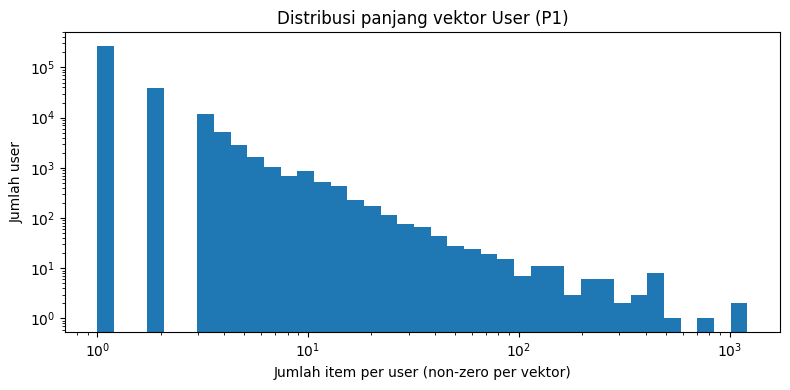

In [141]:
import matplotlib.pyplot as plt

# Contoh vektor user paling aktif (hanya entri non-zero yang ditampilkan)
example_user = items_per_user.idxmax()
row = user_vsm[user_index.get_loc(example_user)]
print(f"Vektor user {example_user}: dimensi {row.shape[1]}, non-zero {row.nnz}")
display(
    pd.Series(row.data, index=item_index[row.indices], name="bobot")
    .sort_values(ascending=False)
    .head(10)
    .to_frame()
)

# Distribusi jumlah item per user (skala log karena sangat menceng)
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(items_per_user, bins=np.logspace(0, np.log10(items_per_user.max() + 1), 40))
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Jumlah item per user (non-zero per vektor)")
ax.set_ylabel("Jumlah user")
ax.set_title("Distribusi panjang vektor User (P1)")
plt.tight_layout()
plt.show()

Seed user: 126001 (5 item)
Bipartit sampel  : 41 simpul, 44 edge
Proyeksi User    : 16 simpul, 42 edge, density 0.350


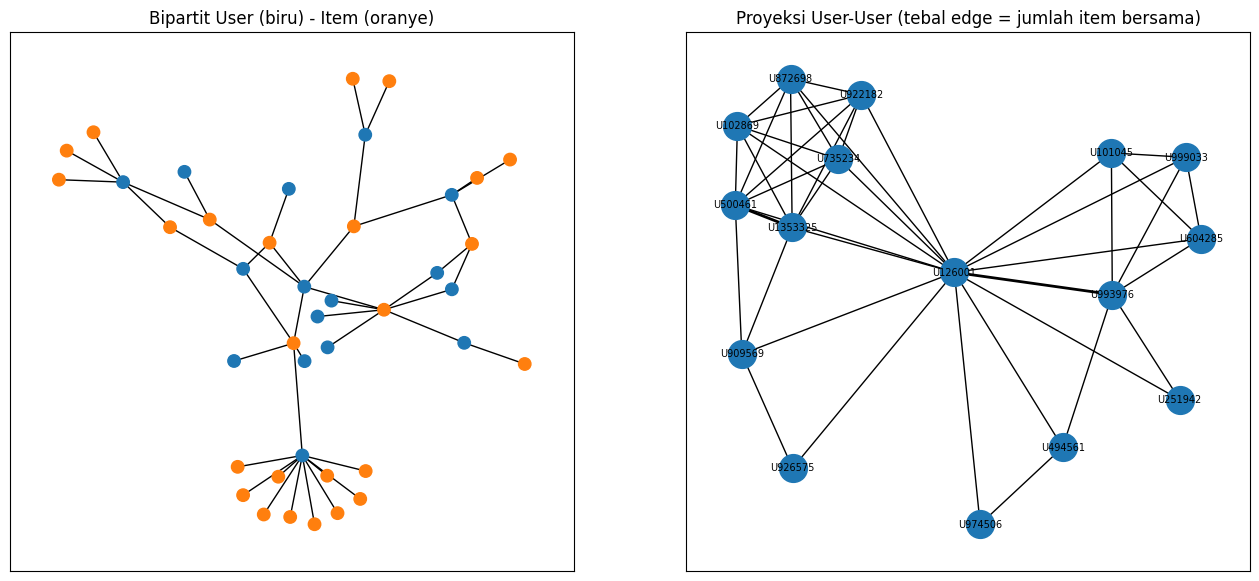

In [142]:
import networkx as nx

# Graf penuh (333 ribu user) terlalu besar untuk digambar, jadi diambil sampel
# ego-network yang reproducible: 1 user acak (seed 42) + user lain yang berbagi item dengannya
rng = np.random.default_rng(42)
candidates = np.where((items_per_user.values >= 3) & (items_per_user.values <= 10))[0]
seed_u = rng.choice(candidates)

seed_items = user_vsm[seed_u].indices
co_users = np.unique(user_vsm[:, seed_items].nonzero()[0])
co_users = co_users[co_users != seed_u]
co_users = rng.choice(co_users, size=min(15, len(co_users)), replace=False)
sample_users = np.r_[seed_u, co_users]

# Graf bipartit User-Item dari sampel
B = nx.Graph()
sample = user_vsm[sample_users]
for r, u in enumerate(sample_users):
    u_node = f"U{user_index[u]}"
    B.add_node(u_node, bipartite=0)
    for j, w in zip(sample[r].indices, sample[r].data):
        i_node = f"I{item_index[j]}"
        B.add_node(i_node, bipartite=1)
        B.add_edge(u_node, i_node, weight=float(w))

# Proyeksi ke simpul User: dua user terhubung jika berbagi item (bobot = jumlah item bersama)
user_nodes = [n for n, d in B.nodes(data=True) if d["bipartite"] == 0]
user_proj = nx.bipartite.weighted_projected_graph(B, user_nodes)

print(f"Seed user: {user_index[seed_u]} ({len(seed_items)} item)")
print(f"Bipartit sampel  : {B.number_of_nodes()} simpul, {B.number_of_edges()} edge")
print(f"Proyeksi User    : {user_proj.number_of_nodes()} simpul, {user_proj.number_of_edges()} edge, "
      f"density {nx.density(user_proj):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(16, 7))
pos = nx.spring_layout(B, seed=42)
colors = ["tab:blue" if B.nodes[n]["bipartite"] == 0 else "tab:orange" for n in B]
nx.draw_networkx(B, pos, ax=ax[0], node_color=colors, node_size=80, with_labels=False)
ax[0].set_title("Bipartit User (biru) - Item (oranye)")

pos_p = nx.spring_layout(user_proj, seed=42)
widths = [user_proj[u][v]["weight"] for u, v in user_proj.edges()]
nx.draw_networkx(user_proj, pos_p, ax=ax[1], node_color="tab:blue", node_size=400,
                 font_size=7, width=widths)
ax[1].set_title("Proyeksi User-User (tebal edge = jumlah item bersama)")
plt.show()

In [143]:
# Ukuran proyeksi User-User penuh: A = X_bin @ X_bin.T (|U| x |U|)
# A[u, v] = jumlah item yang sama-sama diinteraksi oleh user u dan v
user_bin = user_vsm.copy()
user_bin.data[:] = 1

user_cooc = (user_bin @ user_bin.T).tocsr()
user_cooc.setdiag(0)
user_cooc.eliminate_zeros()

n_users = user_cooc.shape[0]
isolated = (np.diff(user_cooc.indptr) == 0).sum()
pd.Series({
    "shape proyeksi": user_cooc.shape,
    "jumlah edge User-User": user_cooc.nnz // 2,
    "density proyeksi": user_cooc.nnz / (n_users * (n_users - 1)),
    "user terisolasi (tak berbagi item)": f"{isolated} ({isolated / n_users:.1%})",
    "memori sparse (MB)": round(
        (user_cooc.data.nbytes + user_cooc.indices.nbytes + user_cooc.indptr.nbytes) / 1e6, 2
    ),
}).to_frame("nilai")

,nilai
shape proyeksi,"(333011, 333011)"
jumlah edge User-User,6241625
density proyeksi,0.000113
user terisolasi (tak berbagi item),38379 (11.5%)
memori sparse (MB),101.2


#### Karakteristik VSM User (subgraph P1: 2015-05-07 s/d sebelum 2015-06-07)

| Karakteristik | Nilai |
|---|---|
| Jumlah vektor (User) | 333.011 |
| Dimensi tiap vektor (jumlah Item) | 119.936 |
| Shape matriks User×Item | (333.011, 119.936) |
| Entri non-zero | 497.987 |
| Density / sparsity | 0,0012% / 99,9988% |
| Memori sparse CSR vs dense | ±5,3 MB vs ±159,8 GB |
| Rata-rata / median item per user | 1,50 / 1 |
| User dengan hanya 1 item | 80,4% |
| Maksimum item per user | 1.216 |

Interpretasi:

1. **Dimensi sangat tinggi, data sangat jarang (sparse).** Setiap user adalah vektor berdimensi ±120 ribu, tetapi rata-rata hanya ±1,5 entri yang terisi. Representasi dense mustahil di memori (±160 GB), sehingga **wajib** memakai sparse matrix.
2. **Distribusi panjang vektor sangat menceng (*long-tail*).** Histogram log-log menunjukkan mayoritas user hanya melihat 1 item, sementara segelintir user sangat aktif (hingga 1.216 item; kemungkinan *crawler*/bot atau *power user*).
3. **Bobot didominasi `VIEWED`.** Sebagian besar entri bernilai 1; nilai besar muncul karena interaksi berulang atau adanya `ADDED_TO_CART`/`BOUGHT`.
4. **Plot networkx (sampel ego-network, seed 42).** Graf bipartit memperlihatkan user (biru) terhubung ke item (oranye). Setelah diproyeksikan ke simpul User, dua user terhubung jika berbagi item; sampel 16 user menghasilkan 42 edge (density 0,35) karena memang dipilih dari lingkungan seed user.
5. **Proyeksi User-User penuh** berukuran (333.011 × 333.011) dengan ±6,24 juta edge (density ±0,011%); ±11,5% user terisolasi karena item yang mereka lihat tidak dilihat user lain. Ukuran proyeksi ini akan dibandingkan dengan proyeksi Item pada soal no. 6.

### 2.1.5 Vector Space Modelling (VSM) terhadap simpul Item

Kebalikan dari no. 4: setiap **Item** direpresentasikan sebagai **vektor di ruang User**:

$$\vec{i} = (w_{1,i}, w_{2,i}, \dots, w_{|U|,i})$$

- **Dimensi** vektor = jumlah user unik $|U|$ pada subgraph.
- $w_{u,i}$ = bobot interaksi yang sama dengan no. 4 (`VIEWED`=1, `ADDED_TO_CART`=3, `BOUGHT`=5).
- Matriks Item×User adalah **transpose** dari matriks User×Item: $X_{item} = X_{user}^{T}$, berukuran $|I| \times |U|$.

Karena hanya transpose, tidak perlu query ulang ke Neo4j; cukup `user_vsm.T` lalu dikonversi ke CSR agar setiap **baris** = satu vektor item.

In [144]:
# Matriks Item x User = transpose User x Item (CSR agar tiap baris = vektor item)
item_vsm = user_vsm.T.tocsr()

display(describe_vsm(item_vsm, "Item", "User").to_frame("nilai"))

# Banyaknya user (entri non-zero) per vektor item
users_per_item = pd.Series(np.diff(item_vsm.indptr), index=item_index, name="users_per_item")
display(users_per_item.describe().to_frame())
print(f"Item yang hanya diinteraksi oleh 1 user: {(users_per_item == 1).mean():.1%}")

,nilai
jumlah vektor (Item),119936
dimensi vektor (jumlah User),333011
shape,"(119936, 333011)"
entri non-zero (nnz),497987
density,0.000012
sparsity,0.999988
memori sparse CSR (MB),4.46
memori jika dense (GB),159.76


,users_per_item
count,119936.000000
mean,4.152106
std,9.716180
min,1.000000
25%,1.000000
50%,2.000000
75%,4.000000
max,616.000000


Item yang hanya diinteraksi oleh 1 user: 48.1%


Vektor item 370653: dimensi 333011, non-zero 616


,bobot
899237,16.0
1273184,11.0
200594,10.0
1125135,7.0
118997,5.0
721239,4.0
1285461,3.0
651129,3.0
1329174,3.0
1107084,3.0


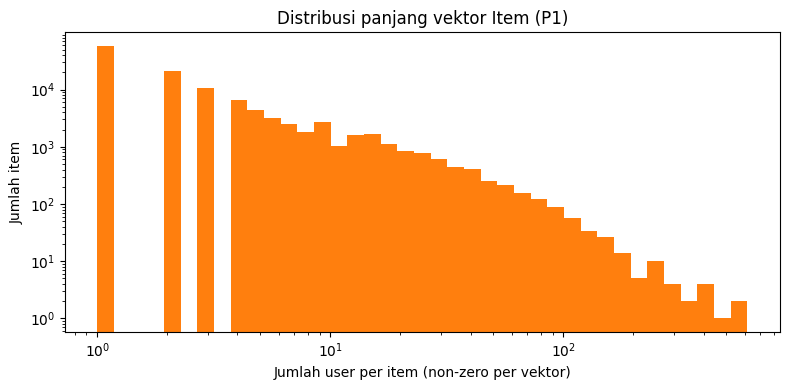

In [145]:
# Contoh vektor item paling populer (hanya entri non-zero yang ditampilkan)
example_item = users_per_item.idxmax()
row = item_vsm[item_index.get_loc(example_item)]
print(f"Vektor item {example_item}: dimensi {row.shape[1]}, non-zero {row.nnz}")
display(
    pd.Series(row.data, index=user_index[row.indices], name="bobot")
    .sort_values(ascending=False)
    .head(10)
    .to_frame()
)

# Distribusi jumlah user per item (skala log karena sangat menceng)
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(users_per_item, bins=np.logspace(0, np.log10(users_per_item.max() + 1), 40),
        color="tab:orange")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Jumlah user per item (non-zero per vektor)")
ax.set_ylabel("Jumlah item")
ax.set_title("Distribusi panjang vektor Item (P1)")
plt.tight_layout()
plt.show()

Seed item: 302126 (6 user)
Bipartit sampel  : 76 simpul, 79 edge
Proyeksi Item    : 16 simpul, 74 edge, density 0.617


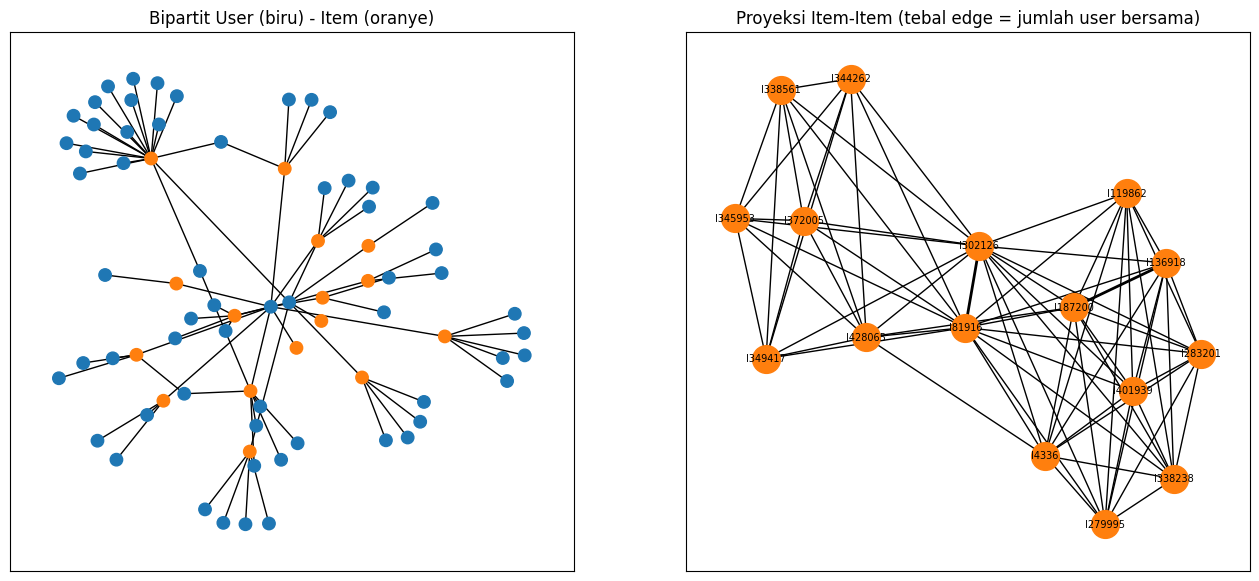

In [146]:
# Sampel ego-network yang reproducible: item acak (seed 42) + item lain yang
# diinteraksi oleh user yang sama. Item tetangga dibatasi <= 20 user agar plot tetap terbaca.
rng = np.random.default_rng(42)
n_users_item = users_per_item.values


def co_items_of(i):
    item_users = item_vsm[i].indices
    co = np.unique(item_vsm[:, item_users].nonzero()[0])
    return co[(co != i) & (n_users_item[co] <= 20)]


# Ambil item acak pertama (urutan permutasi seed 42) yang punya >= 10 item tetangga
candidates = np.where((n_users_item >= 3) & (n_users_item <= 10))[0]
seed_i = next(i for i in rng.permutation(candidates) if len(co_items_of(i)) >= 10)

co_items = co_items_of(seed_i)
co_items = rng.choice(co_items, size=min(15, len(co_items)), replace=False)
sample_items = np.r_[seed_i, co_items]

# Graf bipartit Item-User dari sampel
B_item = nx.Graph()
sample = item_vsm[sample_items]
for r, i in enumerate(sample_items):
    i_node = f"I{item_index[i]}"
    B_item.add_node(i_node, bipartite=1)
    for u, w in zip(sample[r].indices, sample[r].data):
        u_node = f"U{user_index[u]}"
        B_item.add_node(u_node, bipartite=0)
        B_item.add_edge(i_node, u_node, weight=float(w))

# Proyeksi ke simpul Item: dua item terhubung jika diinteraksi user yang sama
item_nodes = [n for n, d in B_item.nodes(data=True) if d["bipartite"] == 1]
item_proj = nx.bipartite.weighted_projected_graph(B_item, item_nodes)

print(f"Seed item: {item_index[seed_i]} ({users_per_item.iloc[seed_i]} user)")
print(f"Bipartit sampel  : {B_item.number_of_nodes()} simpul, {B_item.number_of_edges()} edge")
print(f"Proyeksi Item    : {item_proj.number_of_nodes()} simpul, {item_proj.number_of_edges()} edge, "
      f"density {nx.density(item_proj):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(16, 7))
pos = nx.spring_layout(B_item, seed=42)
colors = ["tab:blue" if B_item.nodes[n]["bipartite"] == 0 else "tab:orange" for n in B_item]
nx.draw_networkx(B_item, pos, ax=ax[0], node_color=colors, node_size=80, with_labels=False)
ax[0].set_title("Bipartit User (biru) - Item (oranye)")

pos_p = nx.spring_layout(item_proj, seed=42)
widths = [item_proj[u][v]["weight"] for u, v in item_proj.edges()]
nx.draw_networkx(item_proj, pos_p, ax=ax[1], node_color="tab:orange", node_size=400,
                 font_size=7, width=widths)
ax[1].set_title("Proyeksi Item-Item (tebal edge = jumlah user bersama)")
plt.show()

In [147]:
# Ukuran proyeksi Item-Item penuh: A = X_bin.T @ X_bin (|I| x |I|)
# A[i, j] = jumlah user yang sama-sama berinteraksi dengan item i dan j
item_bin = item_vsm.copy()
item_bin.data[:] = 1

item_cooc = (item_bin @ item_bin.T).tocsr()
item_cooc.setdiag(0)
item_cooc.eliminate_zeros()

n_items = item_cooc.shape[0]
isolated = (np.diff(item_cooc.indptr) == 0).sum()
pd.Series({
    "shape proyeksi": item_cooc.shape,
    "jumlah edge Item-Item": item_cooc.nnz // 2,
    "density proyeksi": item_cooc.nnz / (n_items * (n_items - 1)),
    "item terisolasi (tak berbagi user)": f"{isolated} ({isolated / n_items:.1%})",
    "memori sparse (MB)": round(
        (item_cooc.data.nbytes + item_cooc.indices.nbytes + item_cooc.indptr.nbytes) / 1e6, 2
    ),
}).to_frame("nilai")

,nilai
shape proyeksi,"(119936, 119936)"
jumlah edge Item-Item,4091755
density proyeksi,0.000569
item terisolasi (tak berbagi user),52875 (44.1%)
memori sparse (MB),65.95


#### Karakteristik VSM Item (subgraph P1: 2015-05-07 s/d sebelum 2015-06-07)

| Karakteristik | Nilai |
|---|---|
| Jumlah vektor (Item) | 119.936 |
| Dimensi tiap vektor (jumlah User) | 333.011 |
| Shape matriks Item×User | (119.936, 333.011) |
| Entri non-zero | 497.987 (sama dengan VSM User, karena hanya transpose) |
| Density / sparsity | 0,0012% / 99,9988% |
| Memori sparse CSR vs dense | ±4,5 MB vs ±159,8 GB |
| Rata-rata / median user per item | 4,15 / 2 |
| Item dengan hanya 1 user | 48,1% |
| Maksimum user per item | 616 (item 370653) |
| Proyeksi Item-Item | (119.936 × 119.936), ±4,09 juta edge, density ±0,057%, 44,1% item terisolasi, ±66 MB |

Interpretasi:

1. **Jumlah vektor lebih sedikit, tetapi dimensinya lebih tinggi.** Ada ±120 ribu vektor item, masing-masing berdimensi ±333 ribu (jumlah user). Total entri non-zero sama dengan VSM User, hanya orientasinya yang dibalik.
2. **Vektor item lebih "padat" daripada vektor user.** Rata-rata 4,15 entri per item (median 2) dibanding 1,5 per user (median 1). Hanya 48,1% item yang punya 1 user, sedangkan pada VSM User 80,4% user hanya punya 1 item. Artinya, informasi per vektor item lebih kaya untuk menghitung kemiripan.
3. **Distribusi tetap *long-tail*.** Histogram log-log memperlihatkan sebagian kecil item populer (hingga 616 user) dan banyak item yang jarang disentuh.
4. **Plot networkx (sampel ego-network, seed 42).** Graf bipartit memperlihatkan item (oranye) beserta user (biru) yang berinteraksi dengannya. Pada proyeksi Item-Item, dua item terhubung jika dilihat/dibeli oleh user yang sama; sampel 16 item membentuk 74 edge (density 0,62), menggambarkan klaster item yang sering diakses bersama.
5. **Proyeksi Item-Item penuh lebih kecil** daripada proyeksi User-User: (119.936 × 119.936) dengan ±4,09 juta edge dan ±66 MB, dibanding ±6,24 juta edge dan ±101 MB pada proyeksi User-User. Namun density-nya lebih tinggi (0,057% vs 0,011%). Perbandingan ini dibahas lebih lanjut pada no. 6.

### 2.1.6 Perbandingan Proyeksi User-User vs Item-Item

Kedua proyeksi dibandingkan dari dua sisi:

- **Efisiensi**: ukuran graf (simpul, edge), memori, dan waktu komputasi proyeksi $XX^T$ vs $X^TX$.
- **Efektivitas**: seberapa berguna proyeksi untuk rekomendasi KNN, yaitu
  - jumlah tetangga per simpul (apakah cukup untuk $k = 5$),
  - *coverage*: persentase user P1 yang bisa diberi rekomendasi,
  - **stabilitas P1 → P2**: apakah simpul yang dipelajari di fold training (P1) masih muncul di fold testing (P2).

In [148]:
import time


def projection_time(binary_matrix, repeat=3):
    # Waktu terbaik dari beberapa kali menghitung proyeksi A @ A.T
    times = []
    for _ in range(repeat):
        t0 = time.perf_counter()
        cooc = (binary_matrix @ binary_matrix.T).tocsr()
        cooc.setdiag(0)
        cooc.eliminate_zeros()
        times.append(time.perf_counter() - t0)
    return min(times)


def sparse_mb(m):
    return (m.data.nbytes + m.indices.nbytes + m.indptr.nbytes) / 1e6


user_deg = np.diff(user_cooc.indptr)  # jumlah tetangga tiap user di proyeksi User-User
item_deg = np.diff(item_cooc.indptr)  # jumlah tetangga tiap item di proyeksi Item-Item

# Coverage: user P1 yang bisa diberi rekomendasi
#   user-based: user punya >= 1 tetangga user
#   item-based: minimal 1 item milik user punya >= 1 tetangga item
coverage_user_based = (user_deg > 0).mean()
coverage_item_based = ((user_bin @ (item_deg > 0).astype(np.float32)) > 0).mean()

# Stabilitas P1 -> P2: apakah user/item di fold testing sudah dikenal di fold training
edges_p2 = run_query(q_edges, start=to_epoch_ms(P2[0]), end=to_epoch_ms(P2[1]))
p2_users = edges_p2["visitorid"].unique()
p2_items = edges_p2["itemid"].unique()
p2_users_seen = np.isin(p2_users, user_index).mean()
p2_items_seen = np.isin(p2_items, item_index).mean()

comparison = pd.DataFrame({
    "Proyeksi User-User": {
        "jumlah simpul": user_cooc.shape[0],
        "jumlah edge": user_cooc.nnz // 2,
        "density": user_cooc.nnz / (user_cooc.shape[0] * (user_cooc.shape[0] - 1)),
        "memori sparse (MB)": round(sparse_mb(user_cooc), 1),
        "waktu proyeksi (detik)": round(projection_time(user_bin), 3),
        "rata-rata tetangga": round(user_deg.mean(), 1),
        "median tetangga": np.median(user_deg),
        "maksimum tetangga": user_deg.max(),
        "simpul terisolasi": f"{(user_deg == 0).mean():.1%}",
        "simpul dengan >= 5 tetangga (k=5)": f"{(user_deg >= 5).mean():.1%}",
        "coverage rekomendasi user P1": f"{coverage_user_based:.1%}",
        "simpul P2 yang sudah ada di P1": f"{p2_users_seen:.1%} dari {len(p2_users)} user",
    },
    "Proyeksi Item-Item": {
        "jumlah simpul": item_cooc.shape[0],
        "jumlah edge": item_cooc.nnz // 2,
        "density": item_cooc.nnz / (item_cooc.shape[0] * (item_cooc.shape[0] - 1)),
        "memori sparse (MB)": round(sparse_mb(item_cooc), 1),
        "waktu proyeksi (detik)": round(projection_time(item_bin), 3),
        "rata-rata tetangga": round(item_deg.mean(), 1),
        "median tetangga": np.median(item_deg),
        "maksimum tetangga": item_deg.max(),
        "simpul terisolasi": f"{(item_deg == 0).mean():.1%}",
        "simpul dengan >= 5 tetangga (k=5)": f"{(item_deg >= 5).mean():.1%}",
        "coverage rekomendasi user P1": f"{coverage_item_based:.1%}",
        "simpul P2 yang sudah ada di P1": f"{p2_items_seen:.1%} dari {len(p2_items)} item",
    },
})
comparison

,Proyeksi User-User,Proyeksi Item-Item
jumlah simpul,333011,119936
jumlah edge,6241625,4091755
density,0.000113,0.000569
memori sparse (MB),101.2,65.9
waktu proyeksi (detik),0.228,0.113
rata-rata tetangga,37.5,68.2
median tetangga,10.0,1.0
maksimum tetangga,22579,6827
simpul terisolasi,11.5%,44.1%
simpul dengan >= 5 tetangga (k=5),65.5%,30.2%


#### Analisis

| Aspek | User-User | Item-Item | Unggul |
|---|---|---|---|
| Jumlah simpul | 333.011 | 119.936 (2,8× lebih sedikit) | Item |
| Jumlah edge | ±6,24 juta | ±4,09 juta (−34%) | Item |
| Memori sparse | ±101 MB | ±66 MB (−35%) | Item |
| Waktu proyeksi | ±0,18 s | ±0,09 s (±2× lebih cepat) | Item |
| Median tetangga | 10 | 1 | User |
| Simpul dengan ≥ 5 tetangga | 65,5% | 30,2% | User |
| Coverage rekomendasi user P1 | 88,5% | 73,8% | User |
| Simpul P2 yang sudah dikenal di P1 | **2,0%** user | **58,7%** item | **Item** |

**1. Efisiensi → Item-Item lebih efisien.**
Jumlah item jauh lebih sedikit daripada jumlah user (±120 ribu vs ±333 ribu), sehingga matriks similarity $|I| \times |I|$ lebih kecil, lebih hemat memori, dan lebih cepat dihitung. Selisih ini akan makin besar jika periode diperpanjang, karena jumlah user tumbuh jauh lebih cepat daripada jumlah item (katalog).

**2. Efektivitas di dalam P1 → User-User tampak lebih unggul, tetapi semu.**
Proyeksi User-User memberi lebih banyak tetangga (median 10) dan coverage lebih tinggi (88,5%). Namun tetangga ini didominasi efek *popular item*: satu item yang dilihat 616 user langsung membuat setiap user tersebut bertetangga dengan 615 user lain, padahal kesamaan mereka hanya 1 item. Akibatnya derajat maksimum mencapai 22.579 (kemungkinan bot) dan banyak tetangga yang kemiripannya lemah. Vektor user juga sangat pendek (80,4% hanya 1 item), sehingga similarity antar user tidak stabil.

Mengapa item terisolasi lebih banyak (44,1%) walaupun vektornya lebih panjang? Item terisolasi jika **semua** user-nya hanya berinteraksi dengan item itu saja. Karena 80,4% user hanya menyentuh 1 item, banyak item *niche* yang hanya dikunjungi user "sekali lewat" sehingga tidak terhubung ke item lain. Sebaliknya, user jarang terisolasi karena kebanyakan user melihat item populer yang juga dilihat orang lain.

**3. Efektivitas lintas periode (P1 → P2) → Item-Item jauh lebih efektif.**
Hanya **2,0%** user di fold testing (P2) yang sudah ada di fold training (P1), sedangkan **58,7%** item di P2 sudah dikenal di P1. Artinya, tetangga user yang dipelajari di P1 tidak bisa dipakai untuk ±98% user P2 (*cold start user*), sementara hubungan antar item yang dipelajari di P1 tetap berlaku untuk sebagian besar item di P2. Katalog item jauh lebih stabil daripada populasi pengunjung.

#### Kesimpulan

**Proyeksi Item-Item lebih baik**, karena:
- **lebih efisien**: graf lebih kecil, memori ±35% lebih hemat, dan komputasi ±2× lebih cepat; dan
- **lebih efektif untuk rekomendasi pada data uji**: similarity antar item bisa dipakai ulang dari P1 ke P2 (58,7% vs 2,0%), dan vektor item lebih kaya (median 2 vs 1 entri), sehingga similarity-nya lebih stabil.

Kelebihan proyeksi User-User (coverage dan jumlah tetangga lebih besar di P1) sebagian besar berasal dari efek item populer, dan tidak berlaku untuk user baru di P2.

Implikasi untuk Analytics (2.2): evaluasi Hit@5/NDCG@5 hanya bisa dilakukan pada user yang muncul di P1 **dan** P2, sehingga user acak sebaiknya dipilih dari irisan tersebut.

### 2.1.7 Perhitungan Similarity pada Proyeksi Item-Item

Berdasarkan kesimpulan no. 6, similarity dihitung pada **proyeksi Item-Item**. Ukuran yang dipakai adalah **cosine similarity** antar vektor item (vektor di ruang User, berbobot `VIEWED`=1, `ADDED_TO_CART`=3, `BOUGHT`=5):

$$\cos(\vec{i}, \vec{j}) = \frac{\vec{i} \cdot \vec{j}}{\lVert \vec{i} \rVert \, \lVert \vec{j} \rVert} = \frac{\sum_{u} w_{u,i}\, w_{u,j}}{\sqrt{\sum_{u} w_{u,i}^2}\, \sqrt{\sum_{u} w_{u,j}^2}}$$

Alasan memilih cosine:
- Nilainya 0–1 untuk bobot non-negatif, sehingga mudah dibandingkan.
- Dinormalisasi oleh panjang vektor, sehingga item populer tidak otomatis mirip dengan semua item (berbeda dengan sekadar menghitung jumlah user bersama seperti pada proyeksi no. 5).
- Bisa dihitung sekaligus untuk semua pasangan dengan operasi sparse: normalisasi L2 tiap baris, lalu $\hat{X}\hat{X}^T$.

Pasangan item yang tidak berbagi user sama sekali memiliki similarity 0, sehingga matriks similarity punya pola non-zero yang sama dengan proyeksi Item-Item.

Matriks similarity: shape (119936, 119936), 4091755 pasangan non-zero, 0.13 detik, 65.9 MB


,cosine
count,8.183510e+06
mean,1.320335e-01
std,2.039381e-01
min,1.337295e-04
25%,1.729827e-02
50%,4.926646e-02
75%,1.428571e-01
max,1.000000e+00


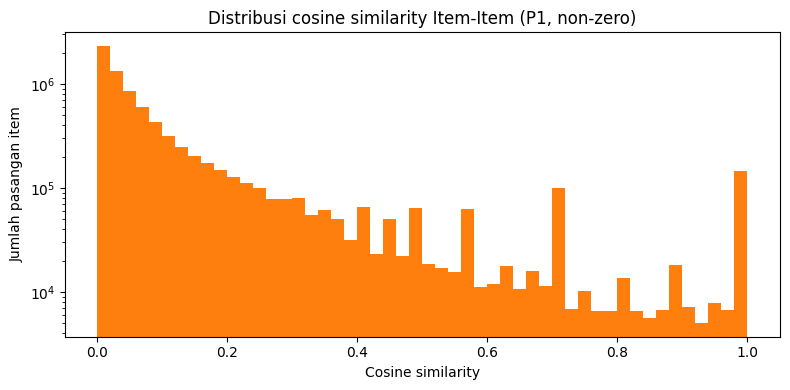

In [149]:
from sklearn.preprocessing import normalize

# Cosine similarity semua pasangan item: normalisasi L2 per baris, lalu X_hat @ X_hat.T
t0 = time.perf_counter()
item_norm = normalize(item_vsm, norm="l2", axis=1)
item_sim = (item_norm @ item_norm.T).tocsr()
item_sim.setdiag(0)  # similarity item dengan dirinya sendiri tidak dipakai
item_sim.eliminate_zeros()
elapsed = time.perf_counter() - t0

print(f"Matriks similarity: shape {item_sim.shape}, {item_sim.nnz // 2} pasangan non-zero, "
      f"{elapsed:.2f} detik, {sparse_mb(item_sim):.1f} MB")
display(pd.Series(item_sim.data, name="cosine").describe().to_frame())

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(item_sim.data, bins=50, color="tab:orange")
ax.set_yscale("log")
ax.set_xlabel("Cosine similarity")
ax.set_ylabel("Jumlah pasangan item")
ax.set_title("Distribusi cosine similarity Item-Item (P1, non-zero)")
plt.tight_layout()
plt.show()

In [150]:
def top_k_similar(sim, idx, k=5):
    # Urutkan skor menurun; bila skor sama, itemId terkecil didahulukan (deterministik)
    row = sim[idx]
    item_ids = item_index[row.indices]
    order = np.lexsort((item_ids, -row.data))[:k]
    return pd.DataFrame({
        "ref_item": item_index[idx],
        "similar_item": item_ids[order],
        "cosine": row.data[order],
    })


# Record acuan: item paling populer di P1 (paling banyak user), dipakai juga sebagai contoh di no. 5
ref_item = users_per_item.idxmax()
ref_idx = item_index.get_loc(ref_item)
print(f"Item acuan: {ref_item} ({users_per_item[ref_item]} user, "
      f"{np.diff(item_sim.indptr)[ref_idx]} item bertetangga)")

top5_python = top_k_similar(item_sim, ref_idx, k=5)
top5_python

Item acuan: 370653 (616 user, 491 item bertetangga)


,ref_item,similar_item,cosine
0,370653,84160,0.198518
1,370653,335975,0.165761
2,370653,10132,0.085480
3,370653,358950,0.078193
4,370653,91755,0.054970


#### (a) CYPHER untuk 5 record dengan similarity tertinggi

Query berikut menghitung cosine similarity **langsung dari graf bipartit di Neo4j** (tanpa bantuan Python) untuk item acuan `$ref`, sehingga hasilnya bisa dicocokkan dengan perhitungan Python di atas.

```cypher
// 1. Vektor item acuan: bobot per visitor pada periode P1, beserta norm-nya
MATCH (ref:Item {itemId: $ref})<-[r1]-(v:Visitor)
WHERE $start <= r1.timestamp < $end
WITH ref, v,
     sum(CASE type(r1) WHEN 'VIEWED' THEN 1.0 WHEN 'ADDED_TO_CART' THEN 3.0 WHEN 'BOUGHT' THEN 5.0 END) AS w_ref
WITH ref, collect({v: v, w: w_ref}) AS ref_vec, sqrt(sum(w_ref * w_ref)) AS norm_ref

// 2. Item lain yang diinteraksi oleh visitor yang sama -> hitung dot product
UNWIND ref_vec AS rv
WITH ref, norm_ref, rv.v AS v, rv.w AS w_ref
MATCH (v)-[r2]->(other:Item)
WHERE other <> ref AND $start <= r2.timestamp < $end
WITH ref, norm_ref, other, v, w_ref,
     sum(CASE type(r2) WHEN 'VIEWED' THEN 1.0 WHEN 'ADDED_TO_CART' THEN 3.0 WHEN 'BOUGHT' THEN 5.0 END) AS w_other
WITH ref, norm_ref, other, sum(w_ref * w_other) AS dot

// 3. Norm vektor item lain (seluruh visitor-nya di P1)
CALL (other) {
    MATCH (other)<-[r3]-(u:Visitor)
    WHERE $start <= r3.timestamp < $end
    WITH u, sum(CASE type(r3) WHEN 'VIEWED' THEN 1.0 WHEN 'ADDED_TO_CART' THEN 3.0 WHEN 'BOUGHT' THEN 5.0 END) AS w
    RETURN sqrt(sum(w * w)) AS norm_other
}

// 4. Cosine = dot / (norm_ref * norm_other), ambil 5 tertinggi
RETURN ref.itemId AS ref_item, other.itemId AS similar_item, dot / (norm_ref * norm_other) AS cosine
ORDER BY cosine DESC, similar_item
LIMIT 5
```

Penjelasan:
- `CASE type(r) ...` mengubah jenis relasi menjadi bobot (sama dengan `EVENT_WEIGHT` di Python); `sum(...)` per visitor menjumlahkan interaksi berulang.
- `collect` + `UNWIND` menyimpan vektor item acuan sekaligus norm-nya, lalu memecahnya kembali per visitor untuk mencari item lain.
- `sum(w_ref * w_other)` per item lain = **dot product** (hanya visitor bersama yang berkontribusi, karena yang lain bernilai 0).
- `CALL (other) { ... }` adalah subquery per item lain untuk menghitung norm vektornya di seluruh visitor P1.
- `ORDER BY cosine DESC, similar_item` + `LIMIT 5` mengambil 5 teratas, dengan `itemId` sebagai *tie-breaker* agar urutannya sama dengan Python.

In [151]:
q_top5_similar = """
MATCH (ref:Item {itemId: $ref})<-[r1]-(v:Visitor)
WHERE $start <= r1.timestamp < $end
WITH ref, v,
     sum(CASE type(r1) WHEN 'VIEWED' THEN 1.0 WHEN 'ADDED_TO_CART' THEN 3.0 WHEN 'BOUGHT' THEN 5.0 END) AS w_ref
WITH ref, collect({v: v, w: w_ref}) AS ref_vec, sqrt(sum(w_ref * w_ref)) AS norm_ref

UNWIND ref_vec AS rv
WITH ref, norm_ref, rv.v AS v, rv.w AS w_ref
MATCH (v)-[r2]->(other:Item)
WHERE other <> ref AND $start <= r2.timestamp < $end
WITH ref, norm_ref, other, v, w_ref,
     sum(CASE type(r2) WHEN 'VIEWED' THEN 1.0 WHEN 'ADDED_TO_CART' THEN 3.0 WHEN 'BOUGHT' THEN 5.0 END) AS w_other
WITH ref, norm_ref, other, sum(w_ref * w_other) AS dot

CALL (other) {
    MATCH (other)<-[r3]-(u:Visitor)
    WHERE $start <= r3.timestamp < $end
    WITH u, sum(CASE type(r3) WHEN 'VIEWED' THEN 1.0 WHEN 'ADDED_TO_CART' THEN 3.0 WHEN 'BOUGHT' THEN 5.0 END) AS w
    RETURN sqrt(sum(w * w)) AS norm_other
}

RETURN ref.itemId AS ref_item, other.itemId AS similar_item, dot / (norm_ref * norm_other) AS cosine
ORDER BY cosine DESC, similar_item
LIMIT 5
"""

top5_cypher = run_query(
    q_top5_similar,
    ref=int(ref_item),
    start=to_epoch_ms(P1[0]),
    end=to_epoch_ms(P1[1]),
)
display(top5_cypher)

# Cocokkan dengan hasil Python (selisih kecil wajar karena Python memakai float32)
same_items = top5_cypher["similar_item"].tolist() == top5_python["similar_item"].tolist()
max_diff = np.abs(top5_cypher["cosine"].values - top5_python["cosine"].values).max()
print(f"Item sama dengan Python: {same_items}, selisih cosine maksimum: {max_diff:.2e}")

,ref_item,similar_item,cosine
0,370653,84160,0.198518
1,370653,335975,0.165761
2,370653,10132,0.085480
3,370653,358950,0.078193
4,370653,91755,0.054970


Item sama dengan Python: True, selisih cosine maksimum: 8.69e-08


#### (b) Menuliskan kembali nilai similarity ke graf

Kelima nilai similarity disimpan sebagai relasi baru `SIMILAR_TO` dari item acuan ke item yang mirip, dengan properti:
- `score`: nilai cosine similarity,
- `method`: metode yang dipakai (`cosine`),
- `period`: periode data yang menjadi dasar perhitungan (`P1`).

```cypher
UNWIND $rows AS row
MATCH (a:Item {itemId: $ref}), (b:Item {itemId: row.itemId})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = row.score, s.method = 'cosine', s.period = $period
```

- `UNWIND $rows` memproses kelima pasangan dalam satu query (satu transaksi).
- `MATCH` mencari kedua simpul lewat `itemId` (memakai index dari constraint unik di 1.3).
- `MERGE` membuat relasi hanya jika belum ada, sehingga cell aman dijalankan ulang tanpa membuat relasi ganda; `SET` memperbarui nilainya.

Hasilnya kemudian ditampilkan dengan:

```cypher
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS ref_item, b.itemId AS similar_item, s.score AS score, s.method AS method, s.period AS period
ORDER BY score DESC
```

In [152]:
q_write_similar = """
UNWIND $rows AS row
MATCH (a:Item {itemId: $ref}), (b:Item {itemId: row.itemId})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = row.score, s.method = 'cosine', s.period = $period
"""

q_show_similar = """
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS ref_item, b.itemId AS similar_item, s.score AS score, s.method AS method, s.period AS period
ORDER BY score DESC
"""

# Nilai yang ditulis = hasil CYPHER (a); ubah ke tipe Python native agar bisa dikirim ke Neo4j
similar_rows = [
    {"itemId": int(item), "score": float(score)}
    for item, score in zip(top5_cypher["similar_item"], top5_cypher["cosine"])
]
similar_rows

[{'itemId': 84160, 'score': 0.1985177125252584},
 {'itemId': 335975, 'score': 0.16576092456199648},
 {'itemId': 10132, 'score': 0.08547960742202877},
 {'itemId': 358950, 'score': 0.07819290527140305},
 {'itemId': 91755, 'score': 0.05496958427683658}]

In [153]:
# Tulis similarity ke Neo4j (query tulis -> routing default WRITE)
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    summary = driver.execute_query(
        q_write_similar,
        ref=int(ref_item),
        rows=similar_rows,
        period="P1",
        database_="neo4j",
    ).summary
print(f"Relasi dibuat: {summary.counters.relationships_created}, "
      f"properti di-set: {summary.counters.properties_set}")

# Tampilkan hasil yang sudah tersimpan di graf
run_query(q_show_similar, ref=int(ref_item))

Relasi dibuat: 0, properti di-set: 15


,ref_item,similar_item,score,method,period
0,370653,84160,0.198518,cosine,P1
1,370653,335975,0.165761,cosine,P1
2,370653,10132,0.085480,cosine,P1
3,370653,358950,0.078193,cosine,P1
4,370653,91755,0.054970,cosine,P1


### 2.1.8 Kondisi Graf Sebelum dan Sesudah Perhitungan Similarity

Fokus pada item acuan **370653** dan 5 item paling mirip hasil no. 7, pada periode P1 (`1430956800000` = 2015-05-07, `1433635200000` = 2015-06-07, epoch milidetik).

**Sebelum**: antar item hanya terhubung **secara tidak langsung** lewat `Visitor` (pola bipartit `Item <- Visitor -> Item`). Kemiripan antar item belum tersimpan di graf.

```cypher
MATCH p = (ref:Item {itemId: 370653})<-[r1:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)
          -[r2:VIEWED|ADDED_TO_CART|BOUGHT]->(o:Item)
WHERE o.itemId IN [84160, 335975, 10132, 358950, 91755]
  AND 1430956800000 <= r1.timestamp < 1433635200000
  AND 1430956800000 <= r2.timestamp < 1433635200000
RETURN p
```

**Sesudah**: graf yang sama ditambah relasi **langsung** `SIMILAR_TO` (berisi properti `score`) dari item acuan ke 5 item termirip.

```cypher
MATCH p = (ref:Item {itemId: 370653})<-[r1:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)
          -[r2:VIEWED|ADDED_TO_CART|BOUGHT]->(o:Item)
WHERE o.itemId IN [84160, 335975, 10132, 358950, 91755]
  AND 1430956800000 <= r1.timestamp < 1433635200000
  AND 1430956800000 <= r2.timestamp < 1433635200000
RETURN p
UNION
MATCH p = (:Item {itemId: 370653})-[:SIMILAR_TO]->(:Item)
RETURN p
```

Penjelasan:
- `MATCH p = ...` menyimpan seluruh path ke variabel `p`, sehingga Neo4j Browser menampilkannya sebagai graf (simpul + relasi), bukan tabel.
- `[r:VIEWED|ADDED_TO_CART|BOUGHT]` membatasi jenis relasi ke relasi interaksi saja, sehingga `SIMILAR_TO` tidak ikut muncul pada kondisi *sebelum*.
- `o.itemId IN [...]` membatasi item tujuan ke 5 item hasil no. 7; filter `timestamp` membatasi ke periode P1.
- `UNION` menggabungkan path interaksi dengan path `SIMILAR_TO` (path duplikat dibuang otomatis).

Kedua query bisa dijalankan langsung di **Neo4j Browser** untuk visualisasi bawaan Neo4j. Di bawah ini query yang sama dijalankan lewat Python (dengan parameter), lalu digambar dengan networkx.

In [154]:
SIM_ITEMS = top5_cypher["similar_item"].astype(int).tolist()
params_sub = {
    "ref": int(ref_item),
    "items": SIM_ITEMS,
    "start": to_epoch_ms(P1[0]),
    "end": to_epoch_ms(P1[1]),
}

# Sebelum: hanya relasi interaksi Item <- Visitor -> Item
q_before = """
MATCH (ref:Item {itemId: $ref})<-[r1:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)
      -[r2:VIEWED|ADDED_TO_CART|BOUGHT]->(o:Item)
WHERE o.itemId IN $items
  AND $start <= r1.timestamp < $end
  AND $start <= r2.timestamp < $end
RETURN DISTINCT ref.itemId AS ref_item, v.visitorId AS visitor, o.itemId AS other_item
"""

# Sesudah: ditambah relasi langsung SIMILAR_TO hasil no. 7 (b)
q_after = """
MATCH (ref:Item {itemId: $ref})-[s:SIMILAR_TO]->(o:Item)
WHERE o.itemId IN $items
RETURN ref.itemId AS ref_item, o.itemId AS other_item, s.score AS score
ORDER BY score DESC
"""

before_df = run_query(q_before, **params_sub)
after_sim_df = run_query(q_after, ref=params_sub["ref"], items=SIM_ITEMS)
if after_sim_df.empty:
    print("Relasi SIMILAR_TO belum ada: jalankan dulu cell penulisan similarity di no. 7 (b).")

n_visitors = before_df["visitor"].nunique()
n_interaction_edges = n_visitors + len(before_df[["visitor", "other_item"]].drop_duplicates())
display(pd.DataFrame({
    "Sebelum": {
        "simpul Item": 1 + before_df["other_item"].nunique(),
        "simpul Visitor": n_visitors,
        "edge interaksi Visitor-Item": n_interaction_edges,
        "edge SIMILAR_TO": 0,
        "hubungan Item-Item": "tidak langsung (2 hop lewat Visitor)",
    },
    "Sesudah": {
        "simpul Item": 1 + before_df["other_item"].nunique(),
        "simpul Visitor": n_visitors,
        "edge interaksi Visitor-Item": n_interaction_edges,
        "edge SIMILAR_TO": len(after_sim_df),
        "hubungan Item-Item": "langsung (1 hop, dengan score)",
    },
}))

# Jumlah visitor bersama vs score similarity per item
shared = before_df.groupby("other_item")["visitor"].nunique().rename("visitor_bersama")
after_sim_df.merge(shared, left_on="other_item", right_index=True)

,Sebelum,Sesudah
simpul Item,6,6
simpul Visitor,121,121
edge interaksi Visitor-Item,266,266
edge SIMILAR_TO,0,5
hubungan Item-Item,tidak langsung (2 hop lewat Visitor),"langsung (1 hop, dengan score)"


,ref_item,other_item,score,visitor_bersama
0,370653,84160,0.198518,52
1,370653,335975,0.165761,51
2,370653,10132,0.085480,11
3,370653,358950,0.078193,1
4,370653,91755,0.054970,30


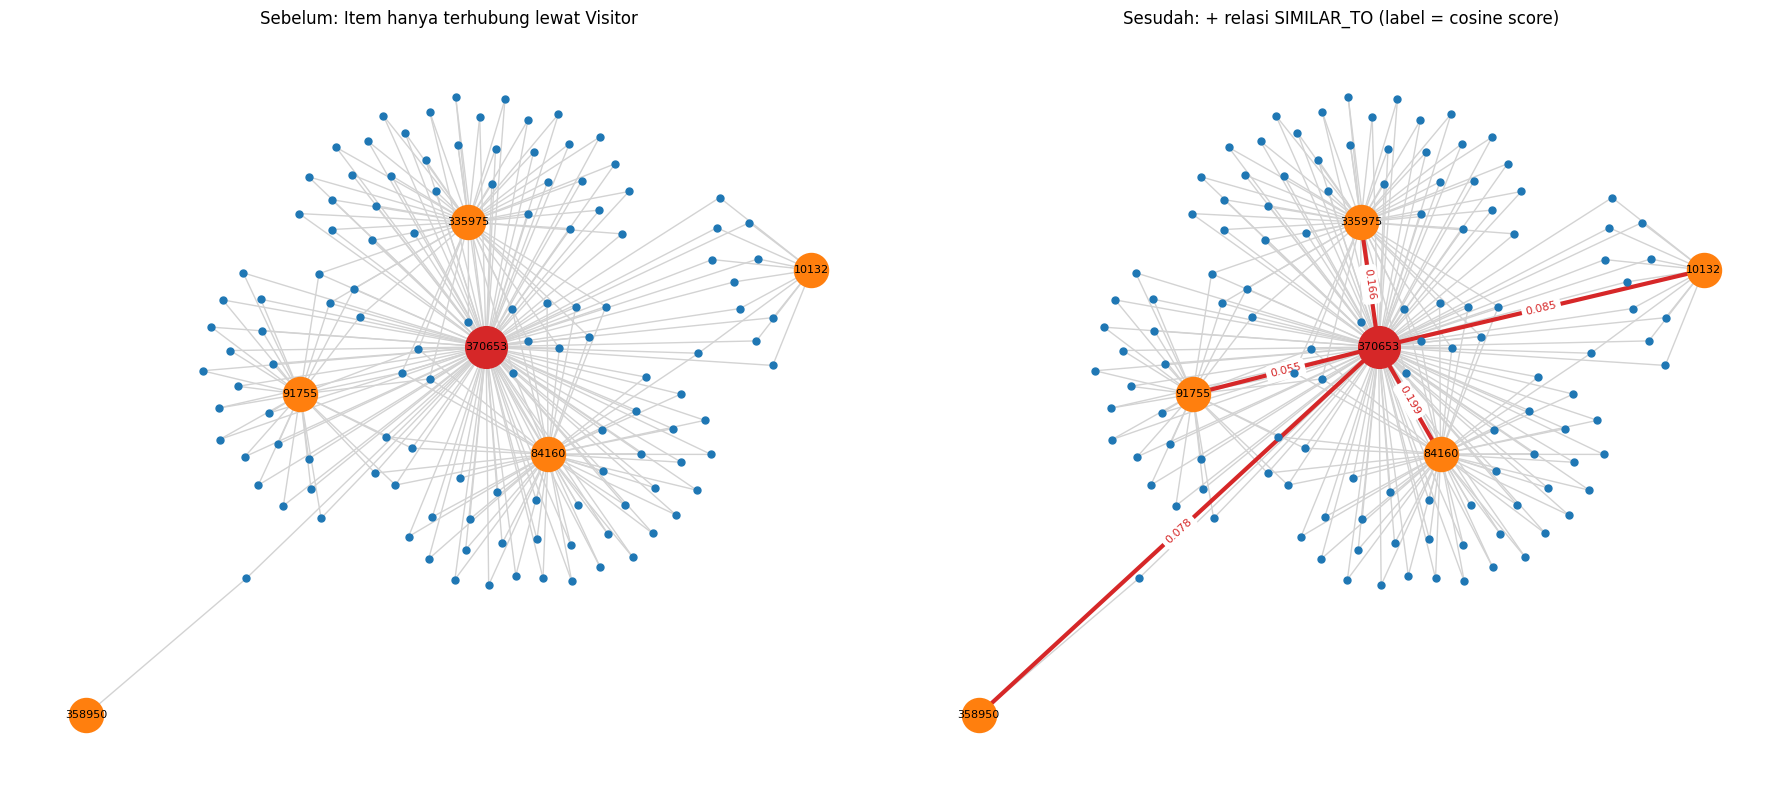

In [155]:
# Graf sebelum: Visitor -- Item (relasi interaksi saja)
G_before = nx.Graph()
for row in before_df.itertuples():
    v_node, ref_node, o_node = f"U{row.visitor}", f"I{row.ref_item}", f"I{row.other_item}"
    G_before.add_edge(v_node, ref_node, kind="interaksi")
    G_before.add_edge(v_node, o_node, kind="interaksi")

# Graf sesudah: graf yang sama + relasi SIMILAR_TO antar item
G_after = G_before.copy()
for row in after_sim_df.itertuples():
    G_after.add_edge(f"I{row.ref_item}", f"I{row.other_item}", kind="SIMILAR_TO", score=row.score)

# Posisi simpul sama di kedua plot agar mudah dibandingkan
pos = nx.spring_layout(G_before, seed=42)
ref_node = f"I{ref_item}"
item_nodes = [n for n in G_before if n.startswith("I") and n != ref_node]
visitor_nodes = [n for n in G_before if n.startswith("U")]

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
panels = [
    (axes[0], G_before, "Sebelum: Item hanya terhubung lewat Visitor"),
    (axes[1], G_after, "Sesudah: + relasi SIMILAR_TO (label = cosine score)"),
]
for ax, G, title in panels:
    interaction = [(u, v) for u, v, d in G.edges(data=True) if d["kind"] == "interaksi"]
    similar = [(u, v) for u, v, d in G.edges(data=True) if d["kind"] == "SIMILAR_TO"]

    nx.draw_networkx_edges(G, pos, edgelist=interaction, edge_color="lightgray", ax=ax)
    nx.draw_networkx_edges(G, pos, edgelist=similar, edge_color="tab:red", width=3, ax=ax)
    nx.draw_networkx_nodes(G, pos, nodelist=visitor_nodes, node_color="tab:blue", node_size=25, ax=ax)
    nx.draw_networkx_nodes(G, pos, nodelist=item_nodes, node_color="tab:orange", node_size=600, ax=ax)
    nx.draw_networkx_nodes(G, pos, nodelist=[ref_node], node_color="tab:red", node_size=900, ax=ax)
    nx.draw_networkx_labels(G, pos, labels={n: n[1:] for n in item_nodes + [ref_node]},
                            font_size=8, ax=ax)
    if similar:
        nx.draw_networkx_edge_labels(
            G, pos, edge_labels={(u, v): f"{G[u][v]['score']:.3f}" for u, v in similar},
            font_size=8, font_color="tab:red", ax=ax,
        )
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

#### Interpretasi

| | Sebelum | Sesudah |
|---|---|---|
| Simpul | 6 Item + 121 Visitor | sama |
| Relasi interaksi Visitor-Item | 266 | sama |
| Relasi `SIMILAR_TO` | 0 | 5 |
| Hubungan antar item | tidak langsung, 2 hop lewat Visitor | langsung, 1 hop dengan `score` |

1. **Sebelum**, item acuan (merah) dan 5 item lain (oranye) hanya terhubung lewat visitor (biru). Untuk mengetahui seberapa mirip dua item, kita harus menelusuri semua visitor bersama dan menghitung cosine setiap kali query dijalankan, seperti query (a) di no. 7.
2. **Sesudah**, hasil perhitungan disimpan sebagai relasi `SIMILAR_TO` (merah, berlabel score). Simpul dan relasi interaksi tidak berubah; yang bertambah hanya 5 relasi baru. Mengambil item termirip kini cukup dengan 1 hop:
   ```cypher
   MATCH (:Item {itemId: 370653})-[s:SIMILAR_TO]->(o:Item)
   RETURN o.itemId, s.score ORDER BY s.score DESC
   ```
   sehingga graf siap dipakai untuk rekomendasi (Analytics 2.2) tanpa menghitung ulang similarity.
3. **Score tidak sebanding dengan jumlah visitor bersama.** Item 84160 dan 335975 berbagi ±50 visitor dengan item acuan dan memang punya score tertinggi. Namun item 358950 hanya berbagi **1** visitor, tetapi score-nya (0,078) lebih tinggi daripada item 91755 yang berbagi 30 visitor (0,055). Ini karena cosine dinormalisasi oleh panjang vektor masing-masing item dan memperhitungkan bobot interaksi: item 358950 punya sedikit visitor dan visitor bersamanya berinteraksi kuat, sedangkan item 91755 punya banyak visitor lain yang tidak berinteraksi dengan item acuan.

## 2.2 Analytics (Maks. skor: 55)

### 2.2.1 Rekomendasi KNN untuk seorang user acak

**Proses acak (reproducible):**
1. *Pool* kandidat = user yang muncul di **P1 (training) dan P2 (testing)**, agar rekomendasinya bisa dievaluasi pada no. 2. Hanya user yang minimal 1 item-nya di P1 punya tetangga di proyeksi Item-Item yang diikutkan, karena tanpa itu KNN tidak menghasilkan kandidat.
2. Pool diurutkan berdasarkan `visitorId` (urutan tetap, tidak bergantung urutan hasil query).
3. Satu user dipilih dengan `np.random.default_rng(42).choice(...)`. Seed yang sama selalu menghasilkan user yang sama.

**Metode: item-based KNN** (sesuai kesimpulan no. 6), memakai matriks cosine similarity Item-Item dari no. 7:
- Untuk setiap item i yang diinteraksi user di P1, ambil **k = 5 tetangga terdekat** $N_k(i) (cosine tertinggi; jika skor sama, `itemId` terkecil didahulukan).
- Skor kandidat item j (yang belum pernah diinteraksi user di P1):



  dengan w_{u,i} bobot interaksi user terhadap item i (`VIEWED`=1, `ADDED_TO_CART`=3, `BOUGHT`=5).
- Kandidat diurutkan menurun berdasarkan skor; **3 teratas** menjadi item yang diiklankan.

In [156]:
# Ground truth P2: himpunan item yang diinteraksi tiap user di fold testing
truth_p2 = edges_p2.groupby("visitorid")["itemid"].agg(set)

# Pool: user di P1 dan P2 yang minimal punya 1 item P1 bertetangga di proyeksi Item-Item
item_has_neighbor = np.diff(item_sim.indptr) > 0
overlap_users = np.intersect1d(user_index.values, truth_p2.index.values)
eligible_users = np.sort([
    v for v in overlap_users
    if item_has_neighbor[user_vsm[user_index.get_loc(v)].indices].any()
])
print(f"User di P1 dan P2: {len(overlap_users)}, eligible untuk KNN: {len(eligible_users)}")

rng = np.random.default_rng(42)
chosen_user = int(rng.choice(eligible_users))
chosen_idx = user_index.get_loc(chosen_user)

chosen_row = user_vsm[chosen_idx]
print(f"User terpilih: {chosen_user}")
display(pd.DataFrame({
    "itemid": item_index[chosen_row.indices],
    "bobot P1": chosen_row.data,
}).sort_values("bobot P1", ascending=False, ignore_index=True))
print(f"Item yang diinteraksi di P2 (ground truth): {sorted(truth_p2[chosen_user])}")

User di P1 dan P2: 4236, eligible untuk KNN: 3393
User terpilih: 123456


,itemid,bobot P1
0,332816,1.0
1,175846,1.0
2,238120,1.0


Item yang diinteraksi di P2 (ground truth): [177822]


#### (a) Skrip Python rekomendasi KNN

- `knn_neighbors(item_idx, k)` mengambil $k$ tetangga terdekat sebuah item dari baris matriks `item_sim` (sparse, sehingga hanya item yang berbagi user yang diperiksa).
- `recommend_knn(user_id, k, n)` menjumlahkan skor tetangga dari semua item user di P1 (dibobot $w_{u,i}$), membuang item yang sudah pernah diinteraksi, lalu mengembalikan $n$ item teratas.
- Tabel di bawahnya memperlihatkan tetangga KNN dari tiap item user, yaitu asal-usul skor rekomendasi.

In [157]:
def knn_neighbors(item_idx, k=5):
    # k tetangga terdekat: cosine menurun, itemId terkecil didahulukan bila skor sama
    row = item_sim[item_idx]
    order = np.lexsort((item_index[row.indices], -row.data))[:k]
    return row.indices[order], row.data[order]


def recommend_knn(user_id, k=5, n=3):
    row = user_vsm[user_index.get_loc(user_id)]
    seen = set(row.indices)
    scores = {}
    for i, w_ui in zip(row.indices, row.data):
        neighbors, sims = knn_neighbors(i, k)
        for j, sim_ij in zip(neighbors, sims):
            if j not in seen:  # item yang sudah diinteraksi di P1 tidak direkomendasikan
                scores[j] = scores.get(j, 0.0) + w_ui * sim_ij
    recs = pd.DataFrame({"itemid": item_index[list(scores)], "score": list(scores.values())})
    return (
        recs.sort_values(["score", "itemid"], ascending=[False, True])
        .head(n)
        .reset_index(drop=True)
    )


# Tetangga KNN (k = 5) dari setiap item user terpilih
neighbor_rows = []
for i, w_ui in zip(chosen_row.indices, chosen_row.data):
    for j, sim_ij in zip(*knn_neighbors(i, k=5)):
        neighbor_rows.append({
            "item_user": item_index[i],
            "bobot": w_ui,
            "tetangga": item_index[j],
            "cosine": sim_ij,
            "kontribusi skor": w_ui * sim_ij,
        })
pd.DataFrame(neighbor_rows)

,item_user,bobot,tetangga,cosine,kontribusi skor
0,332816,1.0,281876,0.425628,0.425628
1,332816,1.0,11185,0.300965,0.300965
2,332816,1.0,415195,0.255377,0.255377
3,332816,1.0,289863,0.245737,0.245737
4,332816,1.0,284887,0.240772,0.240772
5,175846,1.0,70011,0.577350,0.577350
6,175846,1.0,134669,0.577350,0.577350
7,175846,1.0,210416,0.577350,0.577350
8,175846,1.0,238120,0.577350,0.577350
9,175846,1.0,406715,0.577350,0.577350


#### (b) 3 item yang diiklankan untuk $k = 5$

In [158]:
K_NEIGHBORS = 5
N_ADS = 3

recommended = recommend_knn(chosen_user, k=K_NEIGHBORS, n=N_ADS)
recommended.index = recommended.index + 1
recommended.index.name = "rank"
print(f"3 item yang diiklankan untuk user {chosen_user} (item-based KNN, k = {K_NEIGHBORS}):")
recommended

3 item yang diiklankan untuk user 123456 (item-based KNN, k = 5):


,itemid,score
rank,,
1,70011,0.57735
2,134669,0.57735
3,210416,0.57735


### 2.2.2 Evaluasi: Hit@5 dan NDCG@5

Daftar yang dievaluasi adalah **3 item hasil no. 1b**, dicocokkan dengan **ground truth** = item yang benar-benar diinteraksi user tersebut di **P2 (fold testing)**. Relevansi bersifat biner: rel p = 1$ jika item pada peringkat $p$ ada di ground truth, selain itu 0.

- **Hit@5**: bernilai 1 jika minimal satu item dalam 5 rekomendasi teratas relevan.


- **NDCG@5**: memperhitungkan posisi; item relevan di peringkat atas bernilai lebih besar.


dengan |G| jumlah item di ground truth. Karena daftar rekomendasi hanya berisi 3 item, peringkat 4 dan 5 dianggap tidak relevan.

In [159]:
def hit_at_k(recs, truth, k=5):
    return int(any(item in truth for item in list(recs)[:k]))


def ndcg_at_k(recs, truth, k=5):
    rel = [1 if item in truth else 0 for item in list(recs)[:k]]
    dcg = sum(r / np.log2(p + 2) for p, r in enumerate(rel))  # p = 0 -> peringkat 1
    idcg = sum(1 / np.log2(p + 2) for p in range(min(len(truth), k)))
    return dcg / idcg if idcg > 0 else 0.0


truth = truth_p2[chosen_user]
detail = recommended.assign(
    relevan=[int(item in truth) for item in recommended["itemid"]],
    diskon=[1 / np.log2(p + 1) for p in recommended.index],
)
detail["gain"] = detail["relevan"] * detail["diskon"]
display(detail)

idcg = sum(1 / np.log2(p + 2) for p in range(min(len(truth), 5)))
print(f"Ground truth P2 : {sorted(truth)}")
print(f"DCG@5  = {detail['gain'].sum():.4f}")
print(f"IDCG@5 = {idcg:.4f}")
print(f"Hit@5  = {hit_at_k(recommended['itemid'], truth)}")
print(f"NDCG@5 = {ndcg_at_k(recommended['itemid'], truth):.4f}")

,itemid,score,relevan,diskon,gain
rank,,,,,
1,70011,0.57735,0,1.00000,0.0
2,134669,0.57735,0,0.63093,0.0
3,210416,0.57735,0,0.50000,0.0


Ground truth P2 : [177822]
DCG@5  = 0.0000
IDCG@5 = 1.0000
Hit@5  = 0
NDCG@5 = 0.0000


#### Pembanding: evaluasi pada seluruh user eligible

Hasil satu user sangat dipengaruhi kebetulan, jadi metrik yang sama juga dihitung rata-rata untuk **semua user eligible**, dan dibandingkan dengan *baseline* **popularitas** (item dengan visitor terbanyak di P1 yang belum pernah diinteraksi user).

In [160]:
popular_items = edges_p1.groupby("itemid")["visitorid"].nunique().sort_values(ascending=False).index

rows = []
for v in eligible_users:
    seen_ids = set(item_index[user_vsm[user_index.get_loc(v)].indices])
    truth_v = truth_p2[v]
    knn_recs = recommend_knn(v, k=K_NEIGHBORS, n=N_ADS)["itemid"]
    pop_recs = [i for i in popular_items[:N_ADS + len(seen_ids)] if i not in seen_ids][:N_ADS]
    rows.append({
        "Hit@5 KNN": hit_at_k(knn_recs, truth_v),
        "NDCG@5 KNN": ndcg_at_k(knn_recs, truth_v),
        "Hit@5 Popularitas": hit_at_k(pop_recs, truth_v),
        "NDCG@5 Popularitas": ndcg_at_k(pop_recs, truth_v),
    })

eval_all = pd.DataFrame(rows)
print(f"Rata-rata pada {len(eval_all)} user eligible (3 item per user):")
eval_all.mean().to_frame("rata-rata")

Rata-rata pada 3393 user eligible (3 item per user):


,rata-rata
Hit@5 KNN,0.003537
NDCG@5 KNN,0.001897
Hit@5 Popularitas,0.000295
NDCG@5 Popularitas,0.000186


#### Interpretasi Analytics

**Rekomendasi (no. 1).** User acak (seed 42) adalah **123456**, yang di P1 melihat 3 item (332816, 175846, 238120). Dengan item-based KNN $k = 5$, 3 item yang diiklankan adalah **70011, 134669, dan 210416** (skor masing-masing 0,577). Ketiganya berasal dari tetangga item 175846. Item 175846 hanya dilihat 3 user, sehingga 7 tetangganya punya cosine yang sama persis ($1/\sqrt{3} \approx 0{,}577$); urutan di antara item yang seri ditentukan oleh *tie-breaker* `itemId` terkecil.

**Evaluasi (no. 2).** Di P2, user ini hanya berinteraksi dengan item **177822**, yang tidak termasuk dalam rekomendasi, sehingga:

| Metrik | Nilai |
|---|---|
| Hit@5 | **0** |
| DCG@5 | 0 |
| IDCG@5 | 1 (1 item relevan di peringkat 1: $1/\log_2 2$) |
| NDCG@5 | **0** |

Penyebabnya bukan karena pemilihan $k$ atau bobot. Item 177822 memang sudah ada di P1 (dilihat 7 user), tetapi **tidak punya tetangga sama sekali** di proyeksi Item-Item: semua user-nya hanya melihat item itu saja. Cosine-nya terhadap ketiga item user = 0, sehingga item-based KNN tidak mungkin merekomendasikannya. Ini contoh nyata keterbatasan yang dibahas di no. 6 (44,1% item terisolasi).

**Pembanding seluruh user eligible (3.393 user).** Rata-rata Hit@5 item-based KNN ±0,35% dan NDCG@5 ±0,19%, sekitar **12× lebih baik** daripada baseline popularitas (Hit@5 ±0,03%). Nilai absolutnya rendah karena:
1. data sangat sparse (80,4% user hanya melihat 1 item di P1);
2. jarak waktu P1 (Mei–Juni) dan P2 (akhir Agustus–September) sekitar 3 bulan, sehingga minat user sudah banyak berubah;
3. item yang sudah dilihat di P1 sengaja tidak direkomendasikan ulang, padahal sebagian user kembali ke item yang sama di P2.